<a href="https://colab.research.google.com/github/Tobkubos/Systemy_AI/blob/main/SystemyAI_TobiaszKubiak_Lab7_softmax.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Systemy AI – Laboratorium 7
## Zadanie: klasyfikator softmax w PyTorch – pingwiny

Napisz samodzielnie w PyTorch klasyfikator softmax, który rozpoznaje **gatunek pingwina** (Adelie, Chinstrap, Gentoo) na podstawie **dwóch** cech: długości i wysokości dzioba. Znasz te dane z Lab 4 – tym razem nie używasz gotowego `fit`, tylko sam(a) piszesz pętlę uczenia. Wzoruj się na notatniku `SystemyAI_Lab7_wzor.ipynb`.

Dwie cechy wybraliśmy celowo: wynik da się narysować na płaszczyźnie, a zadanie nie jest trywialne (Adelie i Chinstrap częściowo na siebie nachodzą).

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Dane → tensory
1. Wczytaj `sns.load_dataset("penguins")`, zostaw wiersze bez braków w `bill_length_mm`, `bill_depth_mm`, `species`.
2. Zamień gatunki na liczby: `gatunki = ["Adelie", "Chinstrap", "Gentoo"]` → 0, 1, 2.
3. Podział **trzyczęściowy** (dwa razy `train_test_split`, `stratify`, `random_state=42`): najpierw 20% na test, potem z reszty 25% na walidację. Wyjdzie 204 / 69 / 69.
4. `StandardScaler` dopasowany **tylko** na train; przekształć wszystkie trzy zbiory.
5. Tensory: `X_tr`, `X_va`, `X_te` (`float32`) oraz `y_tr`, `y_va`, `y_te` (`long`).

Zbiór walidacyjny posłuży do krzywych uczenia i wyboru learning rate, testowy – raz, na końcu.

In [84]:
import torch
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# 1. Wczytanie i oczyszczenie danych
penguins = sns.load_dataset("penguins")
penguins = penguins.dropna(subset=["bill_length_mm", "bill_depth_mm", "species"]).copy()

# 2. Zamiana gatunków na liczby
gatunki = ["Adelie", "Chinstrap", "Gentoo"]
species_to_idx = {name: idx for idx, name in enumerate(gatunki)}
penguins["species"] = penguins["species"].map(species_to_idx)

X = penguins[["bill_length_mm", "bill_depth_mm"]].values
y = penguins["species"].values.astype(int)

# 3. Podział
# 20% na test
X_temp, X_te_raw, y_temp, y_te = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

# Reszta - 25% na walidację
X_tr_raw, X_va_raw, y_tr_raw, y_va = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

# 4. Standaryzacja
scaler = StandardScaler()
X_tr_scaled = scaler.fit_transform(X_tr_raw)
X_va_scaled = scaler.transform(X_va_raw)
X_te_scaled = scaler.transform(X_te_raw)

# 5. Tensory
X_tr = torch.tensor(X_tr_scaled, dtype=torch.float32)
X_va = torch.tensor(X_va_scaled, dtype=torch.float32)
X_te = torch.tensor(X_te_scaled, dtype=torch.float32)

y_tr = torch.tensor(y_tr_raw, dtype=torch.long)
y_va = torch.tensor(y_va, dtype=torch.long)
y_te = torch.tensor(y_te, dtype=torch.long)

In [85]:
# TEST
assert X_tr.shape == (204, 2) and X_va.shape == (69, 2) and X_te.shape == (69, 2)
assert X_tr.dtype == torch.float32 and y_tr.dtype == torch.long
assert set(y_tr.tolist()) == {0, 1, 2}
assert torch.allclose(X_tr.mean(dim=0), torch.zeros(2), atol=1e-5), "Standaryzacja dopasowana na train"
print("1 OK")

1 OK


---
## 2. Model i strata przed uczeniem
1. `torch.manual_seed(0)`, potem `model = nn.Linear(2, 3)` i `loss_fn = nn.CrossEntropyLoss()`.
2. Policz `loss0` – stratę na zbiorze treningowym **przed** uczeniem (`.item()`).
3. Policz `p0` – prawdopodobieństwa (softmax) dla pierwszych 3 pingwinów treningowych i wypisz je.

In [86]:
# Twoje rozwiązanie
torch.manual_seed(0)
model = nn.Linear(2, 3)
loss_fn = nn.CrossEntropyLoss()

loss0 = loss_fn(model(X_tr), y_tr).item()
p0 = torch.softmax(model(X_tr[:3]), dim=1)

print(f"loss0 = {loss0:.4f}")
print("Prawdopodobieństwa p0:\n", p0)


loss0 = 1.5298
Prawdopodobieństwa p0:
 tensor([[0.1938, 0.5522, 0.2539],
        [0.3298, 0.3845, 0.2857],
        [0.4144, 0.2371, 0.3485]], grad_fn=<SoftmaxBackward0>)


In [87]:
# TEST
assert 0.8 < loss0 < 2.0
assert torch.allclose(p0.sum(dim=1), torch.ones(3))
print("2 OK")

2 OK


*Twoja odpowiedź:* model, który dla każdego pingwina daje wszystkim trzem gatunkom prawdopodobieństwo 1/3, ma stratę dokładnie ln 3 ≈ 1.10. Dlaczego? Czy twoja `loss0` jest blisko tej wartości?

In [88]:
# Zgodnie ze wzorem na wartość straty dla wielu klas, podstawiając 3 gatunki pingwinów do funkcji,
# otrzymujemy logarytm który w przybliżeniu daje wartość 1.10.

# Obliczone Loss0 ma wartość 1.5298 co jest nieco większą wartością, ale wynika to z faktu, że
# wagi na starcie są losowe co za pierwszym razem może skutować dużo większą stratą.

---
## 3. Pętla uczenia
Napisz funkcję `train(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va)`, która:
- ustawia `torch.manual_seed(seed)` i tworzy **nowy** `nn.Linear(2, 3)`, `CrossEntropyLoss` i `optim.SGD(..., lr=lr)`,
- uczy model mini-batchami (`DataLoader` z `shuffle=True`) przez `epochs` epok,
- po każdej epoce zapisuje w słowniku `historia` trzy listy: `"train loss"` (na `X`), `"val loss"` i `"val acc"` (na `X_val`); parametry `X` i `X_val` przydadzą się w punkcie 5,
- zwraca `(model, historia)`.

Uruchom ją dla `lr=0.1` (`model_01, hist_01`) i narysuj dwa wykresy: straty train/val oraz accuracy val w funkcji epoki.

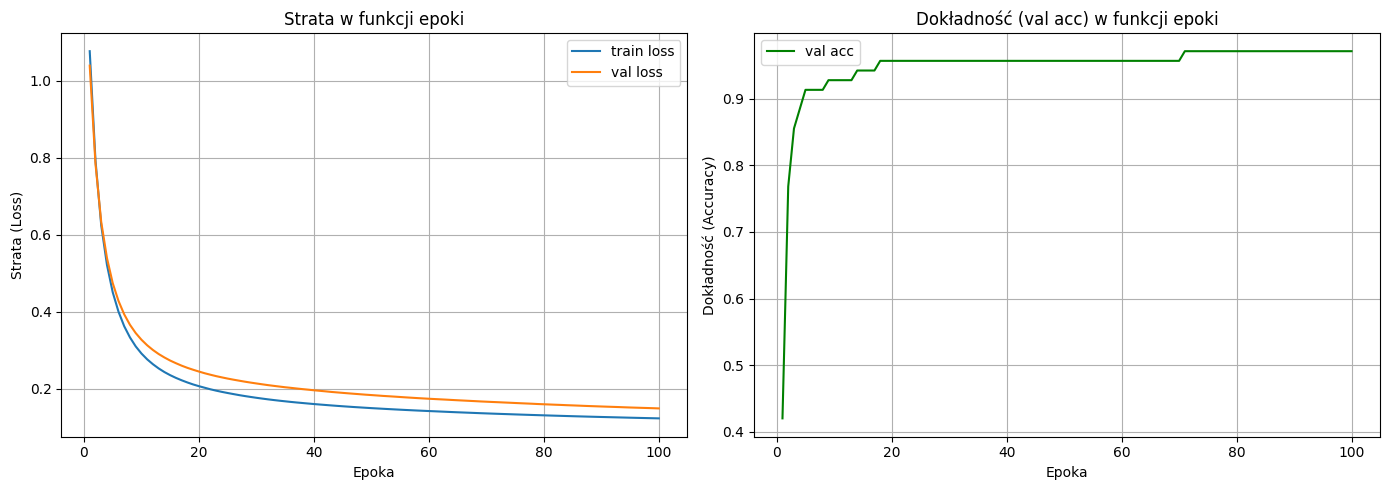

In [89]:
#Twoje rozwiązanie
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

def train(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va):
  torch.manual_seed(seed)
  model = nn.Linear(2, 3)
  loss_fn = nn.CrossEntropyLoss()
  optimizer = optim.SGD(model.parameters(), lr=lr)
  train_loader = DataLoader(TensorDataset(X, y_tr), batch_size=batch_size, shuffle=True)

  historia = {"train loss": [], "val loss": [], "val acc": []}

  for epoch in range(epochs):
    model.train()
    for bx, by in train_loader:
      optimizer.zero_grad()
      out = model(bx)
      loss = loss_fn(out, by)
      loss.backward()
      optimizer.step()

    # Ewaluacja po każdej epoce
    model.eval()
    with torch.no_grad():
      train_outputs = model(X)
      train_loss = loss_fn(train_outputs, y_tr).item()

      val_outputs = model(X_val)
      val_loss = loss_fn(val_outputs, y_va).item()

      preds = torch.argmax(val_outputs, dim=1)
      val_acc = (preds == y_va).float().mean().item()

    historia["train loss"].append(train_loss)
    historia["val loss"].append(val_loss)
    historia["val acc"].append(val_acc)

  return model, historia

# Uczenie z lr=0.1
model_01, hist_01 = train(0.1, X=X_tr, X_val=X_va)

# Wykresy
epochs_range = range(1, 101)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# wykres - loss
ax1.plot(epochs_range, hist_01["train loss"], label="train loss")
ax1.plot(epochs_range, hist_01["val loss"], label="val loss")
ax1.set_title("Strata w funkcji epoki")
ax1.set_xlabel("Epoka")
ax1.set_ylabel("Strata (Loss)")
ax1.legend()
ax1.grid(True)

# wykres - accuracy
ax2.plot(epochs_range, hist_01["val acc"], label="val acc", color="green")
ax2.set_title("Dokładność (val acc) w funkcji epoki")
ax2.set_xlabel("Epoka")
ax2.set_ylabel("Dokładność (Accuracy)")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

In [90]:
# TEST
assert set(hist_01) == {"train loss", "val loss", "val acc"} and len(hist_01["val acc"]) == 100
assert hist_01["train loss"][-1] < hist_01["train loss"][0], "Strata powinna maleć"
assert hist_01["val acc"][-1] > 0.9
print("3 OK")

3 OK


---
## 4. Learning rate
Naucz model dla `lr` ∈ {0.001, 0.01, 0.1, 1.0}. Na jednym wykresie narysuj krzywe **straty treningowej** dla wszystkich czterech wartości, a wyniki końcowe (`val loss`, `val acc` po 100 epokach) zbierz w `pd.DataFrame` o nazwie `wyniki_lr` (indeks: wartości lr).

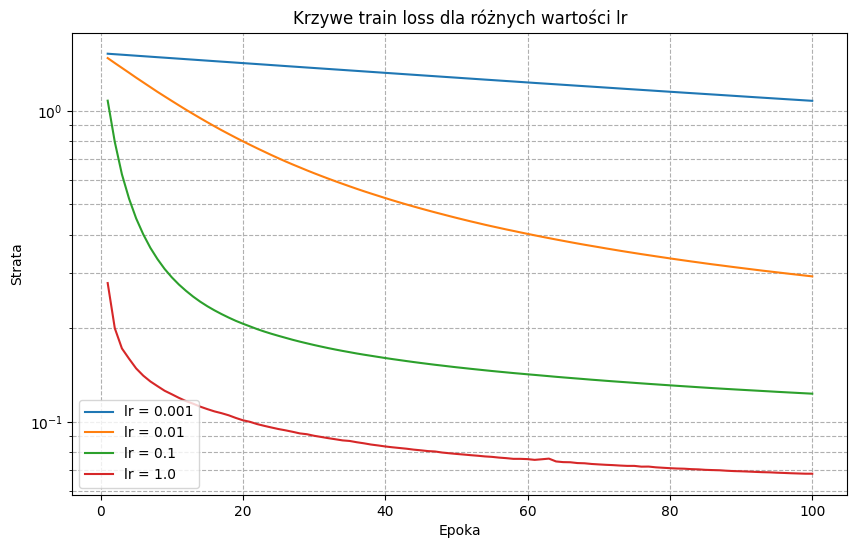

,train loss,val loss,val acc
0.001,1.075902,1.038211,0.420290
0.010,0.293667,0.329397,0.927536
0.100,0.123311,0.149183,0.971014
1.000,0.068216,0.072390,0.971014


In [91]:
import pandas as pd
import matplotlib.pyplot as plt

# Twoje rozwiązanie
lrs = [0.001, 0.01, 0.1, 1.0]
wyniki_lr = pd.DataFrame(columns=["train loss", "val loss", "val acc"])
modele_lr = {}

plt.figure(figsize=(10, 6))

for lr in lrs:
  model_lr, hist_lr = train(lr, X=X_tr, X_val=X_va)
  modele_lr[lr] = model_lr
  wyniki_lr.loc[lr] = [hist_lr["train loss"][-1], hist_lr["val loss"][-1], hist_lr["val acc"][-1]]
  plt.plot(range(1, 101), hist_lr["train loss"], label=f"lr = {lr}")

plt.title("Krzywe train loss dla różnych wartości lr")
plt.xlabel("Epoka")
plt.ylabel("Strata")
plt.yscale("log")
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

wyniki_lr

In [92]:
# TEST
assert list(wyniki_lr.index) == [0.001, 0.01, 0.1, 1.0]
assert wyniki_lr.loc[0.001, "val loss"] > wyniki_lr.loc[0.1, "val loss"]
print("4 OK")

4 OK


*Twoja odpowiedź:* co widać dla lr = 0.001? Który learning rate wybierasz i na podstawie którego zbioru?

In [93]:
# Dla lr 0.001 model uczy się bardzo wolno, przy tak małej ilości epok ma bardzo słabą skuteczność oraz
# największą stratę. Model jest niedouczony. Uczy się zbyt wolno, robi zbyt małe postępy.

# Wybieram model lr = 1, ponieważ po 100 epokach ma najmniejszą stratę i największą skuteczność.

---
## 5. Co daje standaryzacja?
Utwórz `X_tr_raw` i `X_va_raw` – tensory **bez** standaryzacji (surowe milimetry z `X_train`, `X_val`) i naucz model z `lr=0.1`: `train(0.1, X=X_tr_raw, X_val=X_va_raw)`. Porównaj końcową stratę i accuracy z wynikiem z punktu 3. Wynik zapisz w `hist_raw`.

In [94]:
# Twoje rozwiązanie
X_tr_raw = torch.tensor(X_tr_raw, dtype=torch.float32)
X_va_raw = torch.tensor(X_va_raw, dtype=torch.float32)

model_raw, hist_raw = train(0.1, X=X_tr_raw, X_val=X_va_raw)

print(f"Bez standaryzacji -> train loss: {hist_raw['train loss'][-1]:.4f}, "
      f"val loss: {hist_raw['val loss'][-1]:.4f}, val acc: {hist_raw['val acc'][-1]:.4f}")
print(f"Ze standaryzacją  -> train loss: {hist_01['train loss'][-1]:.4f}, "
      f"val loss: {hist_01['val loss'][-1]:.4f}, val acc: {hist_01['val acc'][-1]:.4f}")

Bez standaryzacji -> train loss: 27.6107, val loss: 29.0971, val acc: 0.7971
Ze standaryzacją  -> train loss: 0.1233, val loss: 0.1492, val acc: 0.9710


In [95]:
# TEST
assert hist_raw["val acc"][-1] < hist_01["val acc"][-1]
print("5 OK")

5 OK


*Twoja odpowiedź:* dlaczego bez standaryzacji uczenie idzie tak źle, choć model i dane są te same?

In [96]:
# Bez standaryzacji cechy mają duże wartości i różne skale, co
# powoduje to duże wachania podczas wyliczania gradientu i gwałtowne zmiany wag.

# Przy różnych skalach cech jeden learning rate nie pasuje do wszystkich wag.

---
## 6. Ocena końcowa i porównanie ze scikit-learn
1. Wybierz model z punktu 4 (wybór na podstawie walidacji) i zapisz go jako `model_koncowy`. Policz `acc_test` – accuracy na **teście**.
2. Naucz `LogisticRegression()` ze scikit-learn na tych samych wystandaryzowanych danych treningowych i policz jej accuracy na teście: `acc_sk`.
3. Wypisz prawdopodobieństwa (softmax) Twojego modelu dla pierwszych 5 pingwinów testowych, z nazwami gatunków i prawdziwym gatunkiem.
4. Narysuj obszary decyzyjne `model_koncowy` na płaszczyźnie (wystandaryzowane cechy) z punktami treningowymi – możesz skopiować funkcję `granica` z wzoru.

Wybrany lr na podstawie val loss: 1.0
Accuracy test (PyTorch):      0.9565
Accuracy test (scikit-learn): 0.9275

Prawdopodobieństwa dla pierwszych 5 pingwinów testowych:
Pingwin 1: Adelie: 0.969, Chinstrap: 0.031, Gentoo: 0.000 | Prawdziwy: Adelie
Pingwin 2: Adelie: 0.983, Chinstrap: 0.017, Gentoo: 0.000 | Prawdziwy: Adelie
Pingwin 3: Adelie: 0.000, Chinstrap: 0.005, Gentoo: 0.995 | Prawdziwy: Gentoo
Pingwin 4: Adelie: 0.001, Chinstrap: 0.110, Gentoo: 0.889 | Prawdziwy: Gentoo
Pingwin 5: Adelie: 0.087, Chinstrap: 0.909, Gentoo: 0.004 | Prawdziwy: Chinstrap


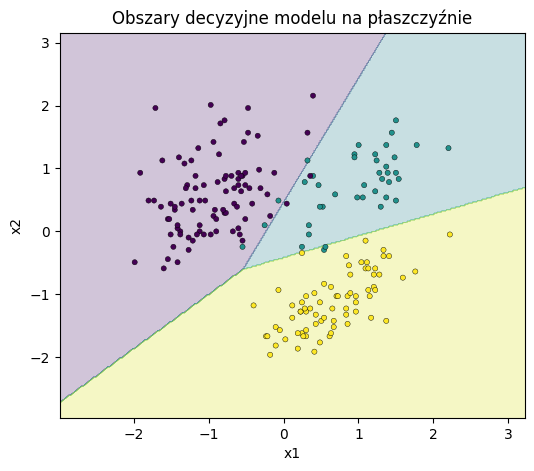

In [97]:
# Twoje rozwiązanie
best_lr = wyniki_lr["val loss"].idxmin()
print(f"Wybrany lr na podstawie val loss: {best_lr}")
model_koncowy = modele_lr[best_lr]

model_koncowy.eval()
with torch.no_grad():
    test_outputs = model_koncowy(X_te)
    preds_test = torch.argmax(test_outputs, dim=1)
    acc_test = (preds_test == y_te).float().mean().item()
    p_test = torch.softmax(model_koncowy(X_te[:5]), dim=1)

from sklearn.linear_model import LogisticRegression
model_sk = LogisticRegression()
model_sk.fit(X_tr_scaled, y_tr_raw)
acc_sk = model_sk.score(X_te_scaled, y_te.numpy())

print(f"Accuracy test (PyTorch):      {acc_test:.4f}")
print(f"Accuracy test (scikit-learn): {acc_sk:.4f}")

print("\nPrawdopodobieństwa dla pierwszych 5 pingwinów testowych:")
for i in range(5):
    prawdziwy = gatunki[y_te[i].item()]
    print(f"Pingwin {i+1}: Adelie: {p_test[i, 0]:.3f}, Chinstrap: {p_test[i, 1]:.3f}, "
          f"Gentoo: {p_test[i, 2]:.3f} | Prawdziwy: {prawdziwy}")

# Obszary decyzyjne
def granica(model, X, y, tytul, softmax=False):
    """Rysuje obszary decyzyjne modelu na płaszczyźnie i punkty danych."""
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300),
                         np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300))
    siatka = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    with torch.no_grad():
        out = model(siatka)
        Z = out.argmax(dim=1) if softmax else (out > 0).squeeze(1)
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.contourf(xx, yy, Z.reshape(xx.shape).numpy(), alpha=0.25, cmap="viridis")
    ax.scatter(X[:, 0], X[:, 1], c=y, s=14, cmap="viridis", edgecolors="k", linewidths=0.3)
    ax.set_title(tytul); ax.set_xlabel("x1"); ax.set_ylabel("x2")
    plt.show()

granica(model_koncowy, X_tr_scaled, y_tr_raw, "Obszary decyzyjne modelu na płaszczyźnie", softmax=True)

In [98]:
# TEST
assert 0.85 < acc_test <= 1.0
assert abs(acc_test - acc_sk) <= 0.06, "Ten sam model - wyniki powinny być bardzo podobne"
assert torch.allclose(p_test.sum(dim=1), torch.ones(5))
print("6 OK")

6 OK


*Twoja odpowiedź:*
1. Jak wypada Twój model w porównaniu ze scikit-learn? Czy to zaskakujące?
2. Gdzie leżą błędy modelu na wykresie obszarów decyzyjnych? Czy model liniowy mógłby tu zrobić coś lepiej?
3. Wymień kroki pętli uczenia i powiedz jednym zdaniem, co robi każdy z nich.

In [99]:
# 1.
# Wybrany lr na podstawie val loss: 1.0
# Accuracy test (PyTorch):      0.9565
# Accuracy test (scikit-learn): 0.9275
# Model radzi sobie lepiej o około 3 punkty procentowe. Nie jest to zaskakujące, różnica 3% jest akceptowalna.
#
# 2. Błędy modelu na wykresie obszarów decyzyjnych dotyczą przypadków na granicach obszarów.
# Osobniki, które zostały źle sklasyfikowane, musiały mieć podobne parametry, bądź wymieszane,
# co doprowadziło do tego, że model nie miał, aż takiej pewności odnośnie wskazania poprawnego gatunku
#
# 3.
# optimizer.zero_grad() – zeruje gradienty z poprzedniego kroku.
# out = model(bx) – wykonuje krok do przodu, obliczając logity dla bieżącej paczki danych.
# loss = loss_fn(out, by) – oblicza wartość funkcji straty określającej błąd modelu na tym batchu.
# loss.backward() – wykonuje propagację wsteczną, obliczając gradienty funkcji straty względem parametrów modelu.
# optimizer.step() – aktualizuje wagi modelu.

---
## 7. Dla chętnych
1. **Batch size:** naucz model z `lr=0.1` dla `batch_size` ∈ {8, 32, 204} (204 = cały zbiór naraz). Porównaj krzywe straty. Który wariant robi najwięcej kroków w epoce? Który uczy się najszybciej w przeliczeniu na epoki?
2. **Adam:** zamień `optim.SGD` na `optim.Adam` (lr = 0.01) i porównaj krzywe z SGD.
3. **Więcej cech:** dodaj `flipper_length_mm` i `body_mass_g` (`nn.Linear(4, 3)`). Ile zyskuje accuracy?

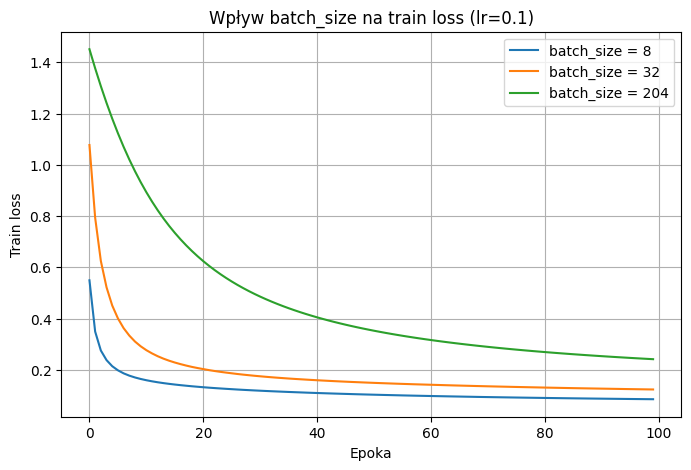

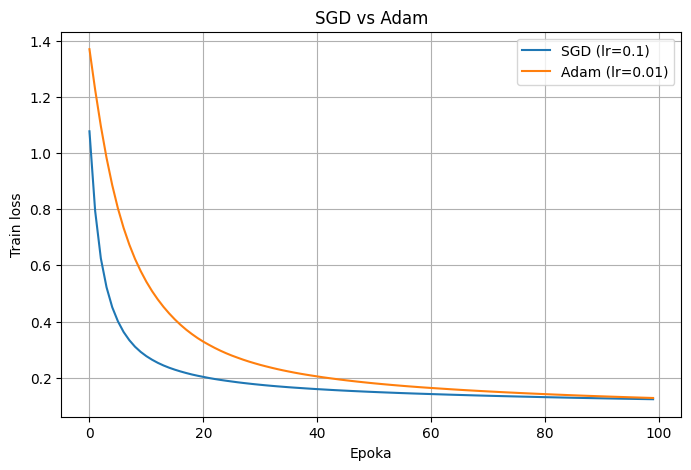

Accuracy test (2 cechy): 0.9565
Accuracy test (4 cechy): 1.0000
Róznica: +0.0435


In [103]:
def train_zad7(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va,
               y=y_tr, y_val=y_va, opt_cls=optim.SGD):
    torch.manual_seed(seed)
    model = nn.Linear(X.shape[1], 3)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = opt_cls(model.parameters(), lr=lr)
    train_loader = DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True)

    historia = {"train loss": [], "val loss": [], "val acc": []}

    for epoch in range(epochs):
        model.train()
        for bx, by in train_loader:
            optimizer.zero_grad()
            out = model(bx)
            loss = loss_fn(out, by)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            train_outputs = model(X)
            train_loss = loss_fn(train_outputs, y).item()

            val_outputs = model(X_val)
            val_loss = loss_fn(val_outputs, y_val).item()

            preds = torch.argmax(val_outputs, dim=1)
            val_acc = (preds == y_val).float().mean().item()

        historia["train loss"].append(train_loss)
        historia["val loss"].append(val_loss)
        historia["val acc"].append(val_acc)

    return model, historia


# 7.1 Batch size: 8, 32, 204
plt.figure(figsize=(8, 5))
for bs in [8, 32, 204]:
    _, hist_bs = train_zad7(0.1, batch_size=bs, X=X_tr, X_val=X_va)
    plt.plot(hist_bs["train loss"], label=f"batch_size = {bs}")

plt.title("Wpływ batch_size na train loss (lr=0.1)")
plt.xlabel("Epoka")
plt.ylabel("Train loss")
plt.legend()
plt.grid(True)
plt.show()


# 7.2 Adam vs SGD
_, hist_adam = train_zad7(lr=0.01, opt_cls=optim.Adam)

plt.figure(figsize=(8, 5))
plt.plot(hist_01["train loss"], label="SGD (lr=0.1)")
plt.plot(hist_adam["train loss"], label="Adam (lr=0.01)")
plt.title("SGD vs Adam")
plt.xlabel("Epoka")
plt.ylabel("Train loss")
plt.legend()
plt.grid(True)
plt.show()


# 7.3
peng_4 = sns.load_dataset("penguins").dropna(
    subset=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "species"]).copy()

X4 = peng_4[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]].values
y4 = peng_4["species"].map(species_to_idx).values.astype(int)

X4_tmp, X4_te, y4_tmp, y4_te = train_test_split(X4, y4, test_size=0.20, stratify=y4, random_state=42)
X4_tr, X4_va, y4_tr, y4_va = train_test_split(X4_tmp, y4_tmp, test_size=0.25, stratify=y4_tmp, random_state=42)

sc4 = StandardScaler()
X4_tr = torch.tensor(sc4.fit_transform(X4_tr), dtype=torch.float32)
X4_va = torch.tensor(sc4.transform(X4_va), dtype=torch.float32)
X4_te = torch.tensor(sc4.transform(X4_te), dtype=torch.float32)

y4_tr = torch.tensor(y4_tr, dtype=torch.long)
y4_va = torch.tensor(y4_va, dtype=torch.long)
y4_te = torch.tensor(y4_te, dtype=torch.long)

m4, hist4 = train_zad7(0.1, X=X4_tr, y=y4_tr, X_val=X4_va, y_val=y4_va)

m4.eval()
with torch.no_grad():
    acc4_test = (m4(X4_te).argmax(dim=1) == y4_te).float().mean().item()

print(f"Accuracy test (2 cechy): {acc_test:.4f}")
print(f"Accuracy test (4 cechy): {acc4_test:.4f}")
print(f"Róznica: {acc4_test - acc_test:+.4f}")